# 04b · Variables — cada idea es una hipótesis que se mide

> Continúa `01b_caso_negocio_aprueba_o_no.ipynb` (**aprueba con 70 o más; con menos de 70 pierde el curso**; clase de interés `Fail`, 69,2 %; costos 5 : 1; métricas: costo por estudiante, *recall* de `Fail` y NPV),
> `02b_eda_aprueba_o_no.ipynb` (decisiones 6 y 7: horas y variables «con y sin») y `03b_preprocesamiento_aprueba_o_no.ipynb` (deja `data/processed/train.joblib`).
> Dataset: `data/student_exam_performance.csv`. Plantilla: `notebooks/04_features.ipynb`. Ejemplo de referencia: `material-del-curso/ejemplo-creditsight/notebooks/04_features.ipynb`.

Crear variables es fácil; saber si **sirven** es lo difícil. Cada idea se mide con **el mismo modelo, los mismos pliegues y la misma métrica**; solo cambia el conjunto de variables. Una idea entra únicamente si la mejora supera el **ruido entre pliegues**.

Este notebook **solo orquesta**: la lógica vive en `src/proyecto/features/engineering.py` (variables y preprocesamiento), `src/proyecto/models/train.py` (pipeline y métricas) y `src/proyecto/data/split.py` (pliegues), todas con pruebas en `tests/`.

**Diferencia con el ejemplo CreditSight.** Allí se partía por cliente (`GroupKFold`) porque un cliente tenía 8 filas, y el objetivo tenía 3 clases. Aquí **cada fila es un estudiante distinto** (`student_id` único), así que los pliegues son **por fila, estratificados por `pass_70`**; y el objetivo tiene 2 clases, con costo 5 : 1 en vez de una matriz 3 × 3.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

import joblib
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier

from proyecto.data.cleaning import LEAK_COLUMNS, TARGET
from proyecto.data.split import make_folds
from proyecto.features.engineering import (CATEGORICAL_BASE, ENGINEERED_FEATURES, NO_SIGNAL_COLUMNS, NUMERIC_BASE,
                                           STAGE4_ADD_MISSING_INDICATOR, STAGE4_DROP, TIMING_COLUMNS, add_features, feature_columns)
from proyecto.models.train import (FALSE_NEGATIVE_COST, FALSE_POSITIVE_COST, build_pipeline, business_metrics,
                                   decision_threshold, encode_target, evaluate_folds)

ROOT = Path.cwd().resolve().parent
SEED = 42

## 0. Cargar los datos de entrenamiento

In [2]:
train_path = ROOT / "data" / "processed" / "train.joblib"
assert train_path.exists(), "Falta data/processed/train.joblib: ejecuta antes el notebook 03b_preprocesamiento_aprueba_o_no."
train = joblib.load(train_path)                      # SOLO entrenamiento: test.joblib NO se abre en esta etapa
X, y = train.drop(columns=[TARGET]), encode_target(train[TARGET])      # y: 1 = Fail (clase de interés), 0 = Pass

FORBIDDEN = {"exam_score", "pass_status", "performance_grade", "performance_level", "questions_correct",
             "questions_attempted", "student_id", "gender", "family_income"}
checks = {
    "80.000 estudiantes de entrenamiento (80 % de 100.000)": len(train) == 80_000,
    "student_id es el índice y no se repite": train.index.is_unique and "student_id" not in train.columns,
    "ninguna columna de fuga ni sensible entre las variables": not (FORBIDDEN | set(LEAK_COLUMNS)) & set(X.columns),
    "las 35 variables base son exactamente las que dejó la etapa 3": set(X.columns) == set(NUMERIC_BASE) | set(CATEGORICAL_BASE),
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
display(result)
print(f"entrenamiento: {train.shape[0]:,} filas x {X.shape[1]} variables · Fail = {y.mean():.1%} (la prueba sigue cerrada)")

80.000 estudiantes de entrenamiento (80 % de 100.000)            True
student_id es el índice y no se repite                           True
ninguna columna de fuga ni sensible entre las variables          True
las 35 variables base son exactamente las que dejó la etapa 3    True
Name: se cumple, dtype: bool

entrenamiento: 80,000 filas x 35 variables · Fail = 69.2% (la prueba sigue cerrada)


## 1. Mis ideas, antes de medirlas

Cada idea sale de lo que midió el EDA. Se escribe **qué variable es**, **por qué podría ayudar** y **si se conoce al momento de avisar** (si no se conoce, es fuga y se descarta).

| # | Idea (variable y cómo se calcula) | Por qué podría ayudar | ¿Se conoce al predecir? |
|---|---|---|---|
| 1 | **`self_study_share`** = `self_study_hours` / `study_hours_per_day` | El EDA mostró que `self_study_hours` es una *parte* de `study_hours_per_day` (siempre ≤). El cociente dice qué tan autónomo es el estudio, algo que ninguna de las dos columnas dice sola. **No se suman** (se contarían dos veces) | ☑ sí |
| 2 | **`prep_total_hours`** = `study_hours_per_day` × `exam_preparation_days` | No es lo mismo estudiar 4 h durante 3 días que durante 30: junta intensidad y duración | ☑ sí |
| 3 | **Sin indicador de vacío** (quitar la columna 0/1 «estaba vacío» que agrega el `Pipeline`) | El EDA mostró que estar vacío **no** se asocia con perder el curso (`Fail` 68,3–69,4 % frente a 69,2 %). Si no aporta, son columnas de más | ☑ sí |
| 4 | **Sin `exam_difficulty`** | Es la variable con más señal entre las dudosas: `Fail` 51,1 % (fácil) / 70,2 % (media) / 85,1 % (difícil). ¿Cuánto pierde el modelo sin ella? | ☐ **por confirmar** con la institución: ¿se conoce la dificultad al momento de avisar? |
| 5 | **Sin `time_management_score` ni `exam_anxiety_level`** (con `exam_difficulty`) | Son datos del examen con 3–10 % de vacíos y con la misma duda de cuándo se miden. ¿Se pierde algo al quitarlos? | ☐ **por confirmar** (igual que la 4) |
| 6 | **Sin las 3 de «con y sin»** (`time_management_score`, `exam_anxiety_level`, `exam_difficulty`) | Es el peor caso: ¿qué pasa si ninguno de los tres se conoce al predecir? | ☑ el modelo sin ellas siempre se puede usar |
| 7 | **Sin las 7 columnas sin señal** (`age`, `internet_access`, `private_tuition`, `daily_screen_time`, `physical_activity_hours`, `online_learning_hours`, `online_course_hours`; AUC ≈ 0,50 en el EDA) | Menos columnas = modelo más simple y una app que pide 7 datos menos; además sale `age`, que incluye menores | ☑ sí |
| 8 | **Propuesta final**: las ideas 3 y 7 **juntas** | Cada recorte se mide por separado; la combinación hay que medirla también, no suponer que suma | ☑ sí |

**Regla de decisión (escrita ANTES de medir):**
- **Añadir una variable** (ideas 1 y 2): se conserva solo si *mejora / ruido* > 1 (el costo baja más que lo que varía entre pliegues) y se conoce al predecir.
- **Quitar columnas** (ideas 3 y 7): se quitan si el costo **no empeora** más que el ruido (*mejora / ruido* > −1): a igual desempeño, menos columnas.
- **«Con y sin»** (ideas 4 a 6): si quitarlas empeora el costo por **mucho más** que el ruido, la variable aporta; entonces la decisión depende de **cuándo se mide en la vida real**, no de la cifra. Se anota como supuesto de negocio.

## 2. Qué hacen las variables nuevas

Antes de medir, un vistazo: ¿las dos variables nuevas están bien construidas y *separan* a quien aprueba de quien pierde a simple vista? (Ver diferencia **no** es lo mismo que mejorar el modelo: un modelo de árboles puede estar ya reconstruyendo el cociente con las columnas originales. Por eso se mide.)

In [3]:
new = add_features(X, engineered=ENGINEERED_FEATURES)
share = new["self_study_share"]
print(f"self_study_share: entre {share.min():.2f} y {share.max():.2f} · vacíos: {share.isna().sum():,} (los de las columnas de origen, no se inventan)")
assert share.dropna().between(0, 1).all(), "el cociente debe estar entre 0 y 1 (self_study_hours <= study_hours_per_day)"
assert not np.isinf(new[list(ENGINEERED_FEATURES)].to_numpy(dtype=float)).any(), "hay infinitos"
assert set(X.columns) == set(NUMERIC_BASE) | set(CATEGORICAL_BASE), "add_features modificó el original"

perfil = new.assign(resultado=train[TARGET])[list(ENGINEERED_FEATURES) + ["study_hours_per_day", "exam_preparation_days", "resultado"]]
display(perfil.groupby("resultado").median().round(3))

self_study_share: entre 0.49 y 0.91 · vacíos: 0 (los de las columnas de origen, no se inventan)


,self_study_share,prep_total_hours,study_hours_per_day,exam_preparation_days
resultado,,,,
Fail,0.700,29.28,2.40,14.0
Pass,0.698,53.13,3.44,18.0


## 3. Validación común: los mismos pliegues para todo

Los pliegues se calculan **una vez** y se reutilizan en cada variante. Son **por fila**, porque cada fila es un estudiante distinto, y **estratificados por `pass_70`** para que cada pliegue tenga el ~69,2 % de `Fail`. Se parten con los 80.000 de entrenamiento; la prueba no interviene.

In [4]:
folds = make_folds(train[TARGET], n_splits=5, seed=SEED)

valid_all = np.concatenate([va for _, va in folds])
assert sorted(valid_all) == list(range(len(train))), "cada estudiante debe validarse exactamente una vez"
for tr_idx, va_idx in folds:
    assert set(tr_idx).isdisjoint(va_idx), "hay estudiantes en los dos lados de un pliegue"
    assert set(train.index[tr_idx]).isdisjoint(train.index[va_idx]), "mismo student_id a los dos lados"
pliegues = pd.DataFrame({"entrenan": [len(t) for t, _ in folds], "se validan": [len(v) for _, v in folds],
                         "% Fail en validación": [round(100 * y[v].mean(), 1) for _, v in folds]},
                        index=[f"pliegue {i}" for i in range(len(folds))])
display(pliegues)
print(f"{len(folds)} pliegues, los MISMOS para todo lo que se compare hoy.")

,entrenan,se validan,% Fail en validación
pliegue 0,64000,16000,69.2
pliegue 1,64000,16000,69.2
pliegue 2,64000,16000,69.2
pliegue 3,64000,16000,69.2
pliegue 4,64000,16000,69.2


5 pliegues, los MISMOS para todo lo que se compare hoy.


## 4. Pipeline base y métricas

El `Pipeline` (`build_pipeline`) hace **todo el preprocesamiento dentro**: mediana + indicador de vacío en las numéricas, categoría «Desconocido» en las categóricas, y el modelo. Se ajusta **solo con el entrenamiento de cada pliegue** (así no hay fuga). El modelo es **LightGBM con parámetros fijos**: aquí no se busca el mejor modelo (eso es la etapa 5), solo se compara el conjunto de variables.

**Cómo se decide a quién avisar.** Con los costos del caso (falso negativo = 5, falso positivo = 1), conviene avisar cuando la probabilidad de `Fail` es al menos **1 / (1 + 5) = 0,167**. Esa es la regla de decisión de todas las variantes.

**Métrica principal: costo por estudiante** (menor es mejor). Cada pliegue da un costo; **la desviación entre pliegues es el «ruido»** con el que se compara cada mejora. Métricas de control: *recall* de `Fail`, NPV (de los que se dejan tranquilos, cuántos aprueban de verdad; hace falta **> 83,3 %** para superar a «avisar a todos»), precisión, alertas por 100, PR-AUC y *log loss* (calidad de las probabilidades; puede mostrar mejoras que el costo no ve).

Antes de medir variables, la referencia sin modelo en estos mismos pliegues:

In [5]:
print(f"umbral de decisión: avisar si P(Fail) >= {decision_threshold():.3f}  (costos FN = {FALSE_NEGATIVE_COST}, FP = {FALSE_POSITIVE_COST}: supuesto a validar con la institución)")

sin_modelo = []
for i, (_, va_idx) in enumerate(folds):
    m = business_metrics(y[va_idx], np.ones(len(va_idx), dtype=bool))      # avisar a todos
    sin_modelo.append(m["cost"])
baseline_cost = float(np.mean(sin_modelo))
print(f"«avisar a todos» (sin modelo): costo = {baseline_cost:.4f} ± {np.std(sin_modelo, ddof=1):.4f} por estudiante  <- lo que un modelo debe vencer")

umbral de decisión: avisar si P(Fail) >= 0.167  (costos FN = 5, FP = 1: supuesto a validar con la institución)
«avisar a todos» (sin modelo): costo = 0.3079 ± 0.0000 por estudiante  <- lo que un modelo debe vencer


## 5. El experimento

Un modelo con **parámetros fijos** y una variante por idea (la referencia primero: las 35 variables de la etapa 3, con indicador de vacío). Cada variante cambia **una sola cosa** respecto de la referencia.

In [6]:
def fixed_model():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1, n_jobs=2)


variants = {
    "referencia (35 variables)":                 dict(),
    "1 + self_study_share":                      dict(engineered=["self_study_share"]),
    "2 + prep_total_hours":                      dict(engineered=["prep_total_hours"]),
    "3 sin indicador de vacío":                  dict(add_missing_indicator=False),
    "4 sin exam_difficulty":                     dict(drop=["exam_difficulty"]),
    "5 sin time_management ni exam_anxiety":     dict(drop=["time_management_score", "exam_anxiety_level"]),
    "6 sin las 3 de «con y sin»":                dict(drop=TIMING_COLUMNS),
    "7 sin las 7 columnas sin señal":            dict(drop=NO_SIGNAL_COLUMNS),
    "8 propuesta final (ideas 3 + 7 juntas)":    dict(drop=STAGE4_DROP, add_missing_indicator=STAGE4_ADD_MISSING_INDICATOR),
}
folds_by_variant = {}
for name, options in variants.items():
    folds_by_variant[name] = evaluate_folds(build_pipeline(fixed_model(), **options), X, y, folds)
    r = folds_by_variant[name]
    print(f"{name:42s} costo = {r['cost'].mean():.4f} ± {r['cost'].std():.4f}   ({r['fit_seconds'].mean():.1f} s por pliegue)")

referencia (35 variables)                  costo = 0.2579 ± 0.0048   (1.4 s por pliegue)


1 + self_study_share                       costo = 0.2581 ± 0.0032   (1.4 s por pliegue)


2 + prep_total_hours                       costo = 0.2591 ± 0.0043   (1.4 s por pliegue)


3 sin indicador de vacío                   costo = 0.2581 ± 0.0047   (1.3 s por pliegue)


4 sin exam_difficulty                      costo = 0.2828 ± 0.0017   (1.3 s por pliegue)


5 sin time_management ni exam_anxiety      costo = 0.2570 ± 0.0023   (1.3 s por pliegue)


6 sin las 3 de «con y sin»                 costo = 0.2815 ± 0.0025   (1.2 s por pliegue)


7 sin las 7 columnas sin señal             costo = 0.2577 ± 0.0036   (1.2 s por pliegue)


8 propuesta final (ideas 3 + 7 juntas)     costo = 0.2584 ± 0.0030   (1.1 s por pliegue)


## 6. Mejora sobre ruido

*Mejora* = cuánto **baja** el costo frente a la referencia (positiva = mejor). *Ruido* = desviación del costo entre pliegues de la variante. **Mejora / ruido** menor que ~1 (en valor absoluto) significa que, con otra partición, el resultado podría cambiar. «Pliegues que gana» cuenta en cuántos de los 5 pliegues la variante tiene menor costo que la referencia (mismos estudiantes de validación).

In [7]:
ref_name = next(iter(variants))
ref = folds_by_variant[ref_name]

def improvement_over_noise(reference, variant):
    # 'reference' y 'variant': valores por pliegue de una métrica donde MENOR es mejor. Positivo = la variante mejora.
    improvement = reference.mean() - variant.mean()
    noise = variant.std(ddof=1)
    return improvement, noise, (improvement / noise if noise > 0 else np.inf)

rows = []
for name, r in folds_by_variant.items():
    imp, noise, ratio = improvement_over_noise(ref["cost"], r["cost"])
    _, _, ratio_ll = improvement_over_noise(ref["log_loss"], r["log_loss"])
    rows.append({"variante": name, "costo": r["cost"].mean(), "± ruido": noise, "mejora": imp, "mejora / ruido": ratio,
                 "pliegues que gana": int((r["cost"] < ref["cost"]).sum()) if name != ref_name else None,
                 "recall Fail": r["recall_fail"].mean(), "NPV": r["npv"].mean(), "precisión Fail": r["precision_fail"].mean(),
                 "alertas por 100": r["alerts_per_100"].mean(), "PR-AUC": r["pr_auc_fail"].mean(),
                 "log loss": r["log_loss"].mean(), "log loss: mejora / ruido": ratio_ll})
table = pd.DataFrame(rows).set_index("variante")
(ROOT / "reports").mkdir(exist_ok=True)
table.round(5).to_csv(ROOT / "reports" / "04_features_tabla.csv")
display(table.round(4))
print(f"Referencia sin modelo («avisar a todos»): costo {baseline_cost:.4f}. Todas las variantes con NPV > {FALSE_NEGATIVE_COST / (FALSE_NEGATIVE_COST + FALSE_POSITIVE_COST):.1%} la superan: "
      f"{bool((table['NPV'] > FALSE_NEGATIVE_COST / (FALSE_NEGATIVE_COST + FALSE_POSITIVE_COST)).all())}")

,costo,± ruido,mejora,mejora / ruido,pliegues que gana,recall Fail,NPV,precisión Fail,alertas por 100,PR-AUC,log loss,log loss: mejora / ruido
variante,,,,,,,,,,,,
referencia (35 variables),0.2579,0.0048,0.0000,0.0000,NaN,0.9884,0.9187,0.7585,90.1962,0.9497,0.3702,0.0000
1 + self_study_share,0.2581,0.0032,-0.0002,-0.0745,4.0,0.9882,0.9177,0.7589,90.1300,0.9497,0.3703,-0.0475
2 + prep_total_hours,0.2591,0.0043,-0.0012,-0.2878,1.0,0.9880,0.9161,0.7586,90.1462,0.9498,0.3702,-0.0208
3 sin indicador de vacío,0.2581,0.0047,-0.0002,-0.0424,3.0,0.9883,0.9181,0.7586,90.1713,0.9497,0.3703,-0.0923
4 sin exam_difficulty,0.2828,0.0017,-0.0250,-14.6260,0.0,0.9913,0.9019,0.7308,93.8850,0.9290,0.4245,-25.1640
5 sin time_management ni exam_anxiety,0.2570,0.0023,0.0009,0.3631,3.0,0.9893,0.9222,0.7570,90.4488,0.9488,0.3727,-1.1645
6 sin las 3 de «con y sin»,0.2815,0.0025,-0.0236,-9.3635,0.0,0.9918,0.9062,0.7306,93.9538,0.9276,0.4270,-26.5598
7 sin las 7 columnas sin señal,0.2577,0.0036,0.0001,0.0381,2.0,0.9882,0.9178,0.7593,90.0775,0.9497,0.3699,0.1561
8 propuesta final (ideas 3 + 7 juntas),0.2584,0.0030,-0.0005,-0.1810,3.0,0.9881,0.9169,0.7590,90.1000,0.9497,0.3702,0.0030


Referencia sin modelo («avisar a todos»): costo 0.3079. Todas las variantes con NPV > 83.3% la superan: True


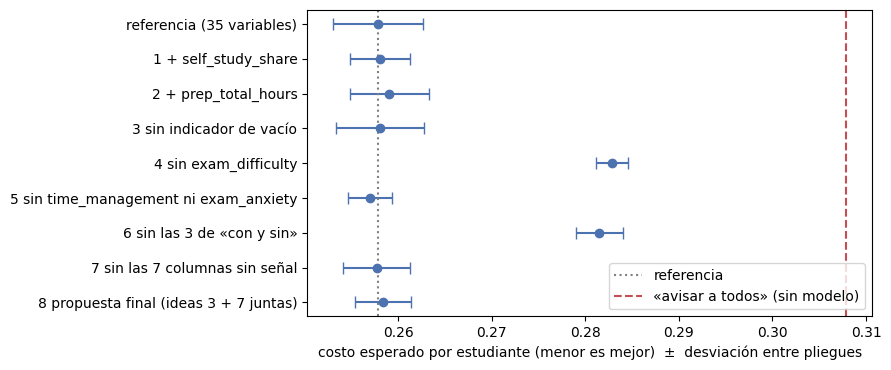

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(table["costo"], range(len(table)), xerr=table["± ruido"], fmt="o", color="#4c72b0", capsize=4)
ax.set_yticks(range(len(table))); ax.set_yticklabels(table.index)
ax.invert_yaxis()
ax.axvline(table.loc[ref_name, "costo"], color="grey", linestyle=":", label="referencia")
ax.axvline(baseline_cost, color="#c44e52", linestyle="--", label="«avisar a todos» (sin modelo)")
ax.set_xlabel("costo esperado por estudiante (menor es mejor)  ±  desviación entre pliegues")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## Cómo leer la tabla

La columna clave es **mejora / ruido**: cuánto baja el costo comparado con lo que varía entre pliegues. Menor que ~1 en valor absoluto = dentro del ruido.

**Lo que muestran los números** (referencia: costo 0,258 por estudiante; «avisar a todos», sin modelo: 0,308):

- **`exam_difficulty` es lo que más pesa, por mucho.** Sin ella el costo sube de 0,258 a 0,283 (≈ 9 a 15 veces el ruido; pierde en los 5 pliegues) y el *log loss* empeora de 0,370 a 0,425. Dicho en negocio: **sin esa variable el modelo pierde la mitad de su ventaja** sobre «avisar a todos» (de 0,050 a 0,025 de costo por estudiante).
- **`time_management_score` y `exam_anxiety_level` no aportan** si `exam_difficulty` se queda: quitar las dos deja el costo igual (0,257 frente a 0,258; 0,4 veces el ruido). El *log loss* sale un poco peor (1,2 veces el ruido), así que **no es concluyente** y por ahora se conservan; si la institución dice que no se conocen al momento de avisar, se pueden quitar **sin perder costo**.
- **Las dos variables nuevas no sirven.** `self_study_share` tiene la misma mediana en quien pierde y en quien aprueba (0,700 frente a 0,698) y no baja el costo (−0,07 veces el ruido). `prep_total_hours` sí se ve distinta a simple vista (mediana 29 h en `Fail` y 53 h en `Pass`), pero **ver diferencia no es mejorar el modelo**: el costo no baja (−0,3 veces el ruido; gana solo en 1 de 5 pliegues). Sus dos factores (`study_hours_per_day` y `exam_preparation_days`) ya están en el modelo.
- **Quitar el indicador de vacío y las 7 columnas sin señal no cuesta nada**: −0,04 y +0,04 veces el ruido, respectivamente. **Juntas** (variante 8) tampoco: 0,2584 frente a 0,2579 (−0,2 veces el ruido). Es lo que decía el EDA: estar vacío no se asocia con perder el curso, y esas 7 columnas tenían AUC ≈ 0,50.
- **El modelo de partida ya supera a «avisar a todos»** (NPV 91,9 % > 83,3 %), pero **avisa a 90 de cada 100 estudiantes**: con el umbral de 0,167 (consecuencia del supuesto 5 : 1) casi nadie queda tranquilo. Si la institución solo puede atender a una parte (p. ej. 30 por cada 100), esta regla de decisión **no es utilizable tal cual**. Qué tan bien ordena el modelo a los estudiantes (PR-AUC 0,95 frente a 0,69 del azar) es una cualidad aparte, y se evalúa en la etapa 5 con la capacidad real. Esto no es un resultado de variables sino una advertencia para lo que sigue.

## Decisión

| # | Idea | Mejora / ruido (costo) | Decisión | Motivo |
|---|---|---|---|---|
| 1 | `self_study_share` | −0,07 | **Descartar** | Sin mejora; la variable ni siquiera separa las clases |
| 2 | `prep_total_hours` | −0,29 | **Descartar** | Se ve diferente a simple vista, pero no mejora el costo; gana 1 de 5 pliegues |
| 3 | Sin indicador de vacío | −0,04 | **Quitar** (regla: no empeora más que el ruido) | Menos columnas; el EDA ya mostraba que el vacío no es informativo |
| 4 | Sin `exam_difficulty` | −14,6 | **Conservar la variable** (condicionada) | Aporta la mitad de la ventaja del modelo; **supuesto de negocio:** debe conocerse al avisar |
| 5 | Sin `time_management_score` ni `exam_anxiety_level` | +0,36 | **No concluyente: conservar por ahora** | Costo igual; *log loss* apenas peor; si no se conocen al avisar, se pueden quitar sin pérdida |
| 6 | Sin las 3 de «con y sin» | −9,4 | **Referencia del peor caso** | Si ninguna se conoce al predecir, el costo sube a ≈ 0,28 (ventaja de 0,026 sobre «avisar a todos») |
| 7 | Sin las 7 columnas sin señal | +0,04 | **Quitar** | Mismo costo; app con 7 datos menos; sale `age`, que incluye menores |
| 8 | Propuesta final (3 + 7) | −0,18 | **Es la propuesta** | 28 variables, sin indicador de vacío; costo 0,2584 ≈ 0,2579 |

> **La condición sobre `exam_difficulty` es un supuesto de negocio, no un resultado técnico.** Si en la práctica la dificultad (o el tiempo y la ansiedad) solo se conoce *después* de avisar al estudiante, usarla sería una fuga, y el costo real sería el de la variante 6. Queda escrito en `reports/04_features.md` y debe confirmarse con la institución antes de la etapa 5.

## Lo más importante de esta etapa

Se probaron ideas razonables y **ninguna variable nueva sirvió**. Eso no es un fracaso: es información. Lo que más movió el resultado fue **entender qué columnas se conocen y cuáles aportan** (etapas 2 y 3), no inventar columnas. Un modelo con 28 variables, sin indicador de vacío, es más fácil de explicar, de desplegar y de mantener.

El código de las variables descartadas se conserva (`add_features`, con la opción `engineered`) porque documenta la prueba; el pipeline final las deja apagadas.

## 7. Qué se lleva el pipeline final

La propuesta de la etapa 4 queda escrita en el código (`STAGE4_DROP` en `src/proyecto/features/engineering.py`) y en `reports/04_features.md`. Aquí se comprueba que la lista final es la que se dice y que no contiene ninguna columna prohibida.

In [9]:
numeric_final, categorical_final = feature_columns(drop=STAGE4_DROP)       # sin variables nuevas: ninguna mejoró; y sin indicador de vacío
final_cols = numeric_final + categorical_final

checks = {
    "28 variables finales (35 base - 7 sin señal)": len(final_cols) == 28,
    "ninguna columna de fuga, sensible ni el objetivo": not (FORBIDDEN | set(LEAK_COLUMNS) | {TARGET}) & set(final_cols),
    "exam_difficulty, time_management_score y exam_anxiety_level siguen: se miden «con y sin» y su momento de medición está por confirmar":
        set(TIMING_COLUMNS) <= set(final_cols),
    "las 7 columnas sin señal salieron (entre ellas age)": not set(NO_SIGNAL_COLUMNS) & set(final_cols),
    "no se añadió ninguna variable nueva (ninguna superó el ruido)": not set(ENGINEERED_FEATURES) & set(final_cols),
    "el indicador de vacío queda apagado (idea 3)": STAGE4_ADD_MISSING_INDICATOR is False,
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
display(result)
print(f"{len(numeric_final)} numéricas + {len(categorical_final)} categóricas")
print("numéricas:", ", ".join(numeric_final))
print("categóricas:", ", ".join(categorical_final))

28 variables finales (35 base - 7 sin señal)                                                                                            True
ninguna columna de fuga, sensible ni el objetivo                                                                                        True
exam_difficulty, time_management_score y exam_anxiety_level siguen: se miden «con y sin» y su momento de medición está por confirmar    True
las 7 columnas sin señal salieron (entre ellas age)                                                                                     True
no se añadió ninguna variable nueva (ninguna superó el ruido)                                                                           True
el indicador de vacío queda apagado (idea 3)                                                                                            True
Name: se cumple, dtype: bool

12 numéricas + 16 categóricas
numéricas: previous_exam_score, previous_gpa, attendance_percentage, assignment_completion_rate, study_hours_per_day, self_study_hours, practice_tests_completed, sleep_hours, stress_level, exam_preparation_days, time_management_score, exam_anxiety_level
categóricas: education_level, school_type, parent_education, urban_rural, class_participation, study_consistency, study_environment, study_method, revision_frequency, notes_quality, sleep_quality, break_frequency, motivation_level, device_availability, educational_app_usage, exam_difficulty


## 8. Las pruebas automáticas

Desde la raíz del repo: `pytest -q`. Hay pruebas para las variables nuevas (cociente seguro, sin infinitos, no modifican el original), para la lista de columnas (ninguna de fuga), para el preprocesamiento (la mediana sale **solo del entrenamiento**, categorías nunca vistas no fallan) y para las métricas de negocio (casos de mano) y los pliegues.

In [10]:
import subprocess

run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_features.py", "tests/test_train.py", "tests/test_split.py",
                      "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print((run.stdout or run.stderr).strip()[-600:])

...........................................                              [100%]
43 passed in 1.05s


## Entregable de esta etapa

- [ ] Cada idea tiene su fila con **mejora / ruido** y una decisión escrita (`reports/04_features.md`).
- [ ] Todas las variantes se midieron con **los mismos pliegues** (por fila, estratificados, porque `student_id` es único).
- [ ] Ninguna variable usa información que no se conoce **al predecir** (o la duda está escrita como supuesto de negocio).
- [ ] El código reutilizable está en `src/proyecto/features/` y el notebook solo lo llama.
- [ ] `pytest` en verde.
- [ ] La institución confirmó **cuándo se miden** `exam_difficulty`, `time_management_score` y `exam_anxiety_level`.
- [ ] El grupo aprobó quitar las 7 columnas sin señal.
- [ ] `test.joblib` no se abrió.

**Siguiente:** `05_torneo.ipynb` (comparar modelos con las 28 variables finales y los mismos pliegues).